In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import stats

df = pd.read_csv("stopping_distance_60_values.csv")
df.columns = df.columns.str.strip()          # remove stray spaces in column names
print(df.head())
print("Number of rows:", len(df))
print("Missing values:", df.isna().sum().sum())

v  = df["Speed(m/s)"].values                  # speed in m/s
d  = df["Simulated Stopping Distance"].values # stopping distance in metres
sd = df["Estimated Uncertainty"].values       # uncertainty of each distance (metres)

   Observation  Speed(Kmh)  Speed(m/s)  Theoretical Stopping Distance  \
0            1   20.000000    5.555556                       6.136173   
1            2   21.694915    6.026365                       6.862775   
2            3   23.389831    6.497175                       7.621656   
3            4   25.084746    6.967985                       8.412817   
4            5   26.779661    7.438795                       9.236257   

   Road Grade Factor  Simulated Stopping Distance  Estimated Uncertainty  \
0           1.000000                     6.898341               0.344917   
1           1.000339                     7.034415               0.351721   
2           1.000678                     7.349341               0.367467   
3           1.001017                     8.589261               0.429463   
4           1.001356                     9.072780               0.453639   

       .  
0  train  
1  train  
2  train  
3  train  
4  train  
Number of rows: 60
Missing values: 0


In [ ]:
# km/h divided by 3.6 must equal m/s
print("Units OK:", np.allclose(df["Speed(Kmh)"]/3.6, v))
print("Speed range:", v.min(), "to", v.max(), "m/s")
print("Distance range:", d.min(), "to", d.max(), "m")

Units OK: True
Speed range: 5.555555556 to 33.33333333 m/s
Distance range: 6.898340926 to 105.4555491 m


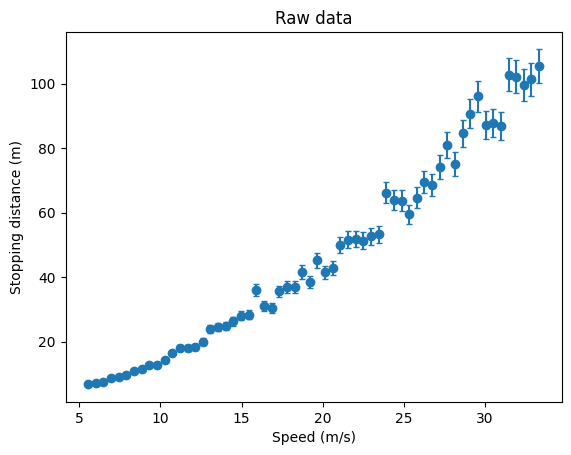

In [ ]:
plt.errorbar(v, d, yerr=sd, fmt="o", capsize=2)
plt.xlabel("Speed (m/s)"); plt.ylabel("Stopping distance (m)")
plt.title("Raw data"); plt.show()

In [ ]:
g = 9.81
model = lambda v, tr, mu: v*tr + v**2/(2*mu*g)

popt, pcov = curve_fit(model, v, d, p0=[1.0, 0.5], sigma=sd, absolute_sigma=True)
tr, mu = popt
tr_err, mu_err = np.sqrt(np.diag(pcov))
dof = len(v) - 2
t_star = stats.t.ppf(0.975, dof)

print(f"tr = {tr:.3f} +/- {tr_err:.3f} s   95% CI: [{tr - t_star*tr_err:.3f}, {tr + t_star*tr_err:.3f}]")
print(f"mu = {mu:.3f} +/- {mu_err:.3f}     95% CI: [{mu - t_star*mu_err:.3f}, {mu + t_star*mu_err:.3f}]")

tr = 0.689 +/- 0.026 s   95% CI: [0.636, 0.741]
mu = 0.682 +/- 0.015     95% CI: [0.653, 0.712]


In [ ]:
t_value = (tr - 0.7) / tr_err
p_value = 2 * stats.t.sf(abs(t_value), dof)
print(f"t = {t_value:.2f}, p = {p_value:.3f}")
if p_value < 0.05:
    print("Reject H0: tr is different from 0.7 s")
else:
    print("Cannot reject H0: tr is consistent with 0.7 s")

t = -0.43, p = 0.669
Cannot reject H0: tr is consistent with 0.7 s


rms error = 3.09 m


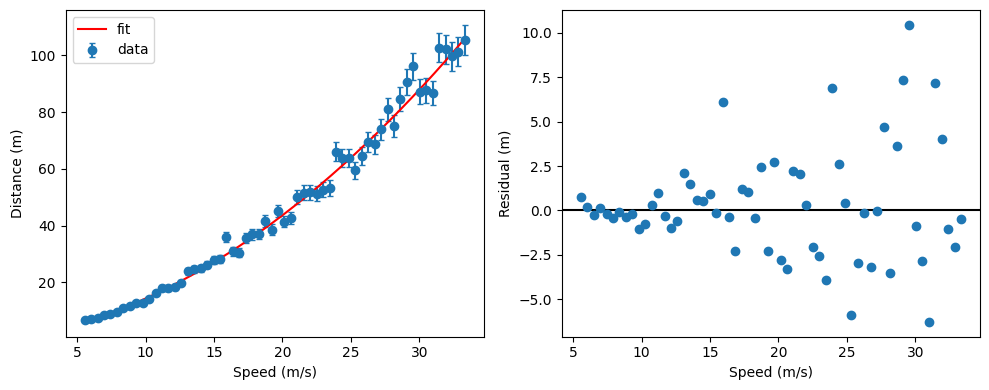

In [ ]:
v_line = np.linspace(v.min(), v.max(), 200)
residuals = d - model(v, tr, mu)
print(f"rms error = {np.sqrt(np.mean(residuals**2)):.2f} m")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.errorbar(v, d, yerr=sd, fmt="o", capsize=2, label="data")
plt.plot(v_line, model(v_line, tr, mu), "r", label="fit")
plt.xlabel("Speed (m/s)"); plt.ylabel("Distance (m)"); plt.legend()

plt.subplot(1, 2, 2)
plt.axhline(0, color="k")
plt.plot(v, residuals, "o")
plt.xlabel("Speed (m/s)"); plt.ylabel("Residual (m)")
plt.tight_layout(); plt.show()